# Adaptive Frame Selection - FAST Colab runner
Runtime -> Change runtime type -> **T4 GPU**. Then run the cells top to bottom (Shift+Enter).

**Why it's faster than before:** each video is decoded once and cached as JPEGs (decoding was ~half the time), frames use 64 visual tokens
(224x224-ish, same for every method), only K in {1,2,4,8} (uniform already plateaus at K=4), 150 test questions for every method,
no distilled selector, small tuning grid. CLIP features are re-encoded on the GPU (a few minutes) so you do **not** need cache.zip.

**Rough time on a T4 (estimates extrapolated from your earlier timings, not measured):**

| Phase | est. time |
|---|---|
| setup + features + frame cache | 10-15 min |
| A baselines (uniform, random, top-K, MMR) | 25-35 min |
| B oracle + random control (K=4) | 15-25 min |
| C tuning | 3-5 min |
| D ours + E adaptive + F ablations | 25-35 min |
| G needle probe | 5-10 min |
| H analysis + demo | 2 min |

**Everything is backed up to your Google Drive** (`MyDrive/afs_backup`) after each phase. If Colab disconnects: re-run cells 1-6, then continue from the phase you were on; finished steps are skipped and reader outputs are cached.

In [1]:
# 1. GPU check - you should see a Tesla T4 (or L4/A100)
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-ed94970f-4898-6fd0-661b-2f1505c00bb3)


In [2]:
# 2. Settings
NQ = 436        # test questions used for EVERY method (must stay the same everywhere). 436 = all (~3x slower)
TRIALS = 40     # needle-probe trials
CFG = 'configs/fast.yaml'

In [3]:
# 3. Mount Drive + backup/restore helpers
from google.colab import drive
drive.mount('/content/drive')
import os, shutil
BK = '/content/drive/MyDrive/afs_backup'
WORK = '/content/afs-project'
ITEMS = ['results', 'cache/reader', 'cache/features', 'cache/text', 'data/subsets']
os.makedirs(BK, exist_ok=True)

def backup():
    for it in ITEMS:
        s = os.path.join(WORK, it)
        if os.path.exists(s):
            shutil.copytree(s, os.path.join(BK, it), dirs_exist_ok=True)
    print('backed up to', BK)

def restore():
    for it in ITEMS:
        s = os.path.join(BK, it)
        if os.path.exists(s):
            shutil.copytree(s, os.path.join(WORK, it), dirs_exist_ok=True)
            print('restored', it)

def sh(cmd):
    get_ipython().system(cmd)

Mounted at /content/drive


In [4]:
p = BK + '/afs-project.zip'
if os.path.exists(p): os.remove(p)

In [5]:
# 4. Get the project: upload afs-project.zip ONCE (it is then kept on your Drive for later sessions)
zp = BK + '/afs-project.zip'
if not os.path.exists(zp):
    from google.colab import files
    up = files.upload()                       # pick afs-project.zip
    shutil.copy(list(up)[0], zp)
sh(f'cd /content && unzip -q -o "{zp}"')
os.chdir(WORK)
print(os.getcwd(), os.listdir('.'))

Saving afs-project.zip to afs-project.zip
/content/afs-project ['src', 'data', 'results', 'pyproject.toml', 'requirements.txt', 'tests', 'scripts', 'cache', 'run_all.sh', 'README.md', 'configs', '.gitignore']


In [6]:
# 5. Install, restore any earlier progress from Drive, download the 100 videos, rebuild the same question subset
sh('pip install -q transformers accelerate opencv-python-headless pandas pyyaml matplotlib datasets huggingface_hub sentencepiece protobuf tqdm')
restore()
sh('python scripts/00_download_small_nextqa.py --n_videos 100 2>&1 | tail -4')
sh(f'python scripts/01_build_subset.py --config {CFG} --kind nextqa')

restored results
restored cache/reader
restored cache/features
restored cache/text
restored data/subsets
  nextqa:
    ann_csv: data/raw/nextgqa/annotations/val.csv
    video_dir: data/raw/nextgqa/videos
Then: python scripts/01_build_subset.py --kind nextqa   (questions whose video is missing are skipped automatically)
[nextqa] 581 questions (2777 skipped: video missing, 0 skipped: answer not parseable)
wrote 581 questions (145 dev / 436 test) -> data/subsets/nextqa.jsonl


In [7]:
# 6. CLIP features for all videos (GPU: a few minutes; already-encoded videos are skipped)
sh(f'python scripts/02_cache_features.py --config {CFG} --subset nextqa')
backup()

config.json: 100% 4.10k/4.10k [00:00<00:00, 12.1MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

pytorch_model.bin: downloading bytes:  16% 96.0M/599M [00:01<00:04, 110MB/s, 8.25MB/s  ]
pytorch_model.bin: reconstructing file:  19% 113M/599M [00:01<00:06, 79.1MB/s]
pytorch_model.bin: downloading bytes:  23% 138M/599M [00:01<00:03, 130MB/s, 10.5MB/s  ] 
pytorch_model.bin: reconstructing file:  31% 187M/599M [00:01<00:03, 129MB/s, 13.0MB/s  ] 
pytorch_model.bin: downloading bytes:  32% 189M/599M [00:01<00:02, 154MB/s, 15.2MB/s  ]
pytorch_model.bin: downloading bytes:  52% 314M/599M [00:02<00:01, 247MB/s, 25.3MB/s  ]
pytorch_model.bin: reconstructing file:  53% 314M/599M [00:02<00:02, 139MB/s, 23.9MB/s  ]
pytorch_model.bin: downloading bytes:  57% 343M/599M [00:02<00:01, 201MB/s, 29.0MB/s  ]
pytorch_model.bin: downloading bytes:  69% 411M/599M [00:02<00:00, 217MB/s, 33.1MB/s  ]
pytorch_model.bin: reconstructing file:  81% 485M/599M [00:04<00:01, 63.1MB/s, 37.9MB/s  ]

In [8]:
sh('rm -rf results/nextqa/test results/nextqa/report')

## Quick smoke test (~2-3 min, includes downloading the 7 GB reader once)
Uses the *dev* split so it never pollutes the real test results. Success = a line like `==> uniform K=2 acc=...`.

In [ ]:
sh(f'python scripts/03_run_selector.py --config {CFG} --subset nextqa --split dev --selectors uniform ours --ks 2 --limit 5')

## Phase A - baselines (K = 1, 2, 4, 8)

In [10]:
sh(f'python scripts/03_run_selector.py --config {CFG} --subset nextqa --split test --selectors uniform random topk mmr --limit {NQ}')
backup()

Loading weights: 100% 824/824 [00:30<00:00, 26.92it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
uniform K=1: 100% 436/436 [02:40<00:00,  2.72it/s]
==> uniform                K=1     acc=0.635  meanK=1.0  GFLOPs=1192
uniform K=2: 100% 436/436 [00:57<00:00,  7.55it/s]
==> uniform                K=2     acc=0.677  meanK=2.0  GFLOPs=1898
uniform K=4: 100% 436/436 [01:32<00:00,  4.69it/s]
==> uniform                K=4     acc=0.688  meanK=4.0  GFLOPs=3310
uniform K=8: 100% 436/436 [02:53<00:00,  2.52it/s]
==> uniform                K=8     acc=0.688  meanK=8.0  GFLOPs=6136
random K=1: 100% 436/436 [00:41<00:00, 10.42it/s]
==> random     

## Phase B - oracle upper bound at K=4, plus the random best-of-T control (same 8 candidates each)

In [11]:
sh(f'python scripts/04_run_oracle.py --config {CFG} --subset nextqa --split test --ks 4 --n_cand 8 --limit {NQ}')
sh(f'python scripts/04_run_oracle.py --config {CFG} --subset nextqa --split test --ks 4 --n_cand 8 --limit {NQ} --control')
backup()

Loading weights: 100% 824/824 [00:30<00:00, 26.92it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
oracle K=4: 100% 436/436 [09:37<00:00,  1.33s/it]
==> oracle K=4: acc=0.821 (best of <= 8 subsets)
Loading weights: 100% 824/824 [00:31<00:00, 26.56it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnin

## Phase C - tune diversity / temporal weights on DEV only (best values are written into the config automatically)

In [9]:
sh(f'python scripts/05_tune_diversity.py --config {CFG} --subset nextqa --K 4 --limit 60 --w_div_grid 0 0.5 1 2 --w_time_grid 0 0.5 1 --apply {CFG}')
sh(f'grep -nE "^  w_div|^  w_time" {CFG}')
backup()

config.json: 100% 1.37k/1.37k [00:00<00:00, 3.27MB/s]
model.safetensors.index.json: 100% 65.4k/65.4k [00:00<00:00, 107MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/3.98G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):  43% 3.21G/7.51G [00:37<00:38, 111MB/s,  112MB/s  ]
Reconstructing (incomplete total...):  47% 3.55G/7.51G [00:37<00:22, 178MB/s,  113MB/s  ]
Reconstructing (incomplete total...):  57% 4.28G/7.51G [00:41<00:17, 181MB/s,  165MB/s  ]
Reconstructing (incomplete total...):  86% 6.47G/7.51G [00:56<00:08, 121MB/s,  129MB/s  ]
Reconstructing (incomplete total...):  96% 7.20G/7.51G [00:58<00:01, 230MB/s,  208MB/s  ]
Reconstructing (incomplete total...): 100% 7.51G/7.51G [00:59<00:00, 238MB/s,  230MB/s  ]

Fetching 2 files: 100% 2/2 [01:00<00:00, 30.04s/it]
Download complete: 100% 6.56G/6.56G [01:00<00:00, 62.5MB/s, 62.5MB/s  ]
Download

## Phase D - our selector

In [12]:
sh(f'python scripts/03_run_selector.py --config {CFG} --subset nextqa --split test --selectors ours --limit {NQ}')
backup()

Loading weights: 100% 824/824 [00:30<00:00, 26.75it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
ours K=1: 100% 436/436 [00:36<00:00, 11.95it/s]
==> ours                   K=1     acc=0.649  meanK=1.0  GFLOPs=1191
ours K=2: 100% 436/436 [00:55<00:00,  7.81it/s]
==> ours                   K=2     acc=0.690  meanK=2.0  GFLOPs=1898
ours K=4: 100% 436/436 [00:00<00:00, 596.35it/s]
==> ours                   K=4     acc=0.704  meanK=4.0  GFLOPs=3311
ours K=8: 100% 436/436 [02:38<00:00,  2.75it/s]
==> ours                   K=8     acc=0.688  meanK=8.0  GFLOPs=6137
backed up to /content/drive/MyDrive/afs_backup


## Phase E - adaptive budget (here `--ks` is the TARGET MEAN K, so it is compared with fixed K at the same average cost)

In [13]:
sh(f'python scripts/03_run_selector.py --config {CFG} --subset nextqa --split test --selectors ours_adaptive ours_adaptive_entropy --ks 4 8 --limit {NQ}')
backup()

Loading weights: 100% 824/824 [00:30<00:00, 26.83it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
  [ours_adaptive] calibrated param=0.188 -> mean K=4.00
ours_adaptive K=4: 100% 436/436 [01:09<00:00,  6.31it/s]
==> ours_adaptive          K=4     acc=0.695  meanK=4.0  GFLOPs=3306
  [ours_adaptive] calibrated param=0.1364 -> mean K=8.00
ours_adaptive K=8: 100% 436/436 [02:59<00:00,  2.43it/s]
==> ours_adaptive          K=8     acc=0.697  meanK=8.0  GFLOPs=6147
  [ours_adaptive_entropy] calibrated param=0.3873 -> mean K=4.00
ours_adaptive_entropy K=4: 100% 436/436 [01:09<00:00,  6.29it/s]
==> ours_adaptive_entropy  K=4     acc=0.681  mean

## Phase F - ablations (K=4)

In [14]:
sh(f'python scripts/03_run_selector.py --config {CFG} --subset nextqa --split test --selectors ours_no_div ours_no_time ours_no_rel ours_unweighted --ks 4 --limit {NQ}')
backup()

Loading weights: 100% 824/824 [00:31<00:00, 26.52it/s]
[reader] Qwen/Qwen2.5-VL-3B-Instruct: LLM 3.09B params, vision tower 0.67B
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
ours_no_div K=4: 100% 436/436 [00:43<00:00,  9.98it/s]
==> ours_no_div            K=4     acc=0.665  meanK=4.0  GFLOPs=3311
ours_no_time K=4: 100% 436/436 [00:00<00:00, 599.58it/s]
==> ours_no_time           K=4     acc=0.697  meanK=4.0  GFLOPs=3311
ours_no_rel K=4: 100% 436/436 [00:07<00:00, 56.09it/s]
==> ours_no_rel            K=4     acc=0.697  meanK=4.0  GFLOPs=3310
ours_unweighted K=4: 100% 436/436 [00:49<00:00,  8.79it/s]
==> ours_unweighted        K=4     acc=0.683  meanK=4.0  GFLOPs=3311
backed up to /content/drive/MyDrive/afs_bac

## Phase G - synthetic needle probe

In [ ]:
sh(f'python scripts/07_needle_probe.py --config {CFG} --subset nextqa --trials {TRIALS} --min_frames 40 --ks 1 2 4 8 --use_reader')
backup()

## Phase H - analysis, demo figure, download everything

In [15]:
sh(f'python scripts/08_analyze.py --config {CFG} --subset nextqa --split test')
sh(f'python scripts/09_demo.py --config {CFG} --subset nextqa --K 4')
backup()

             selector  K   n   acc  mean_K   gflops  gflops_total  latency_s  select_ms  ci_lo  ci_hi
                  mmr  1 436 0.624     1.0 1190.910      2739.710      0.136      0.091  0.578  0.670
                  mmr  2 436 0.647     2.0 1897.582      3446.382      0.180      0.121  0.603  0.688
                  mmr  4 436 0.672     4.0 3310.672      4859.472      0.296      0.210  0.628  0.716
                  mmr  8 436 0.697     8.0 6136.441      7685.241      0.552      0.290  0.654  0.739
               oracle  4 436 0.821     4.0 3309.950      3309.950      0.296      0.000  0.784  0.856
        oracle_random  4 436 0.839     4.0 3309.992      3309.992      0.295      0.000  0.803  0.874
                 ours  1 436 0.649     1.0 1190.995      2739.795      0.138      0.677  0.603  0.693
                 ours  2 436 0.690     2.0 1897.752      3446.552      0.187      1.021  0.647  0.734
                 ours  4 436 0.704     4.0 3310.728      4859.528      0.297      

acc_vs_K


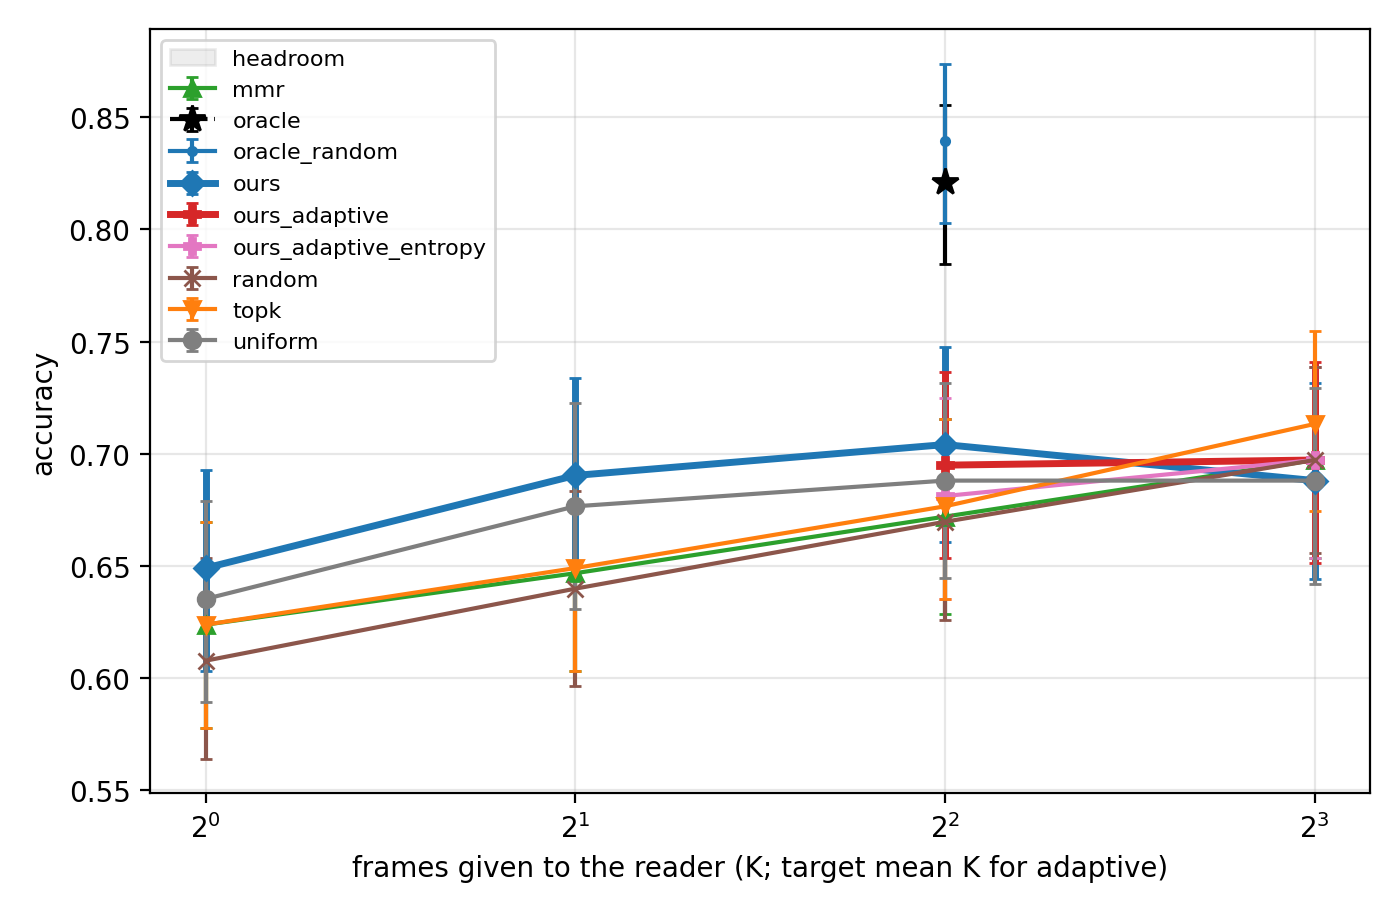

pareto_gflops


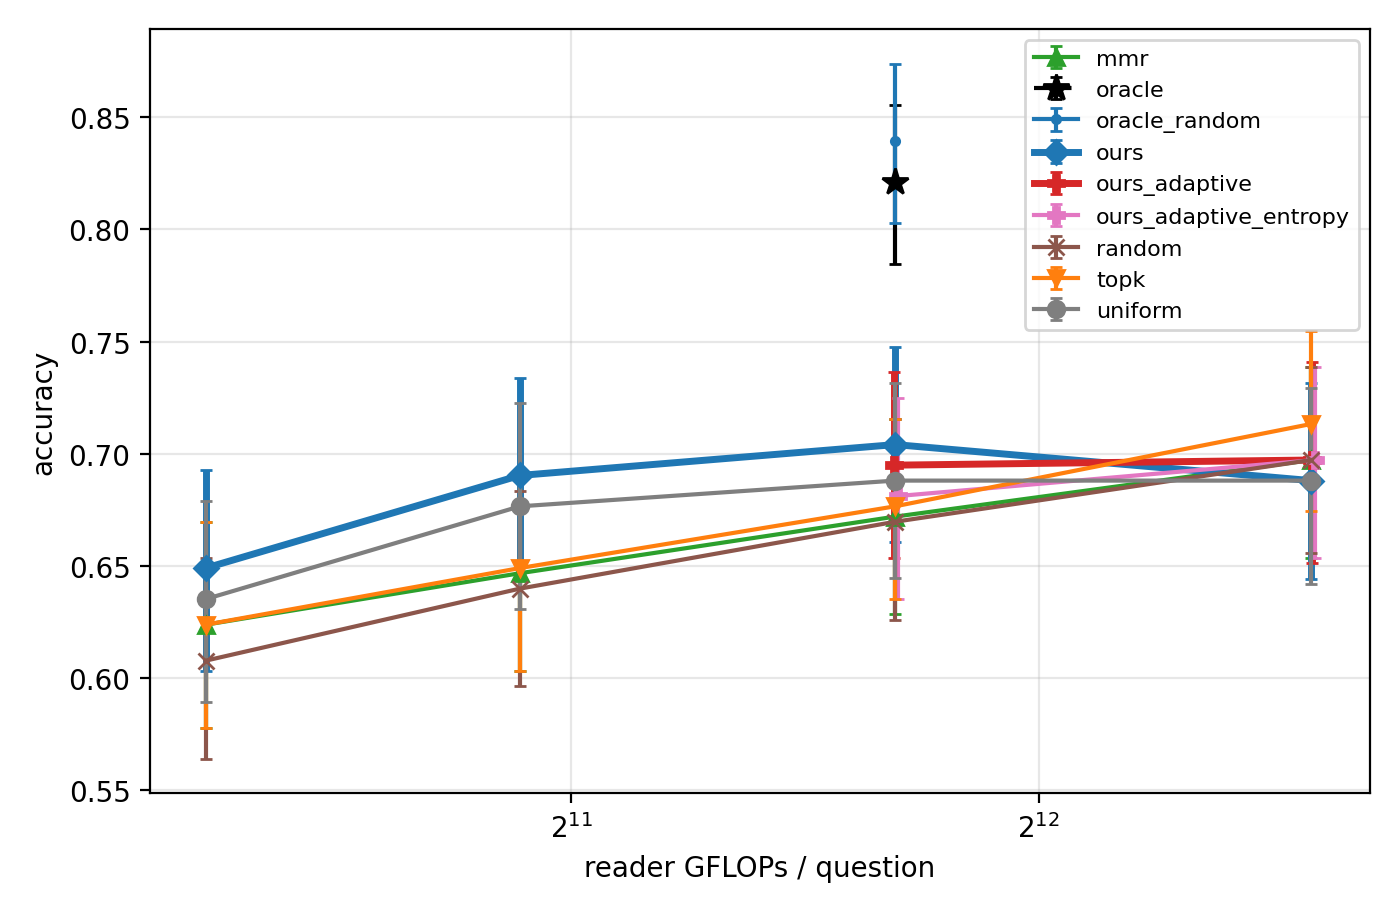

pareto_latency


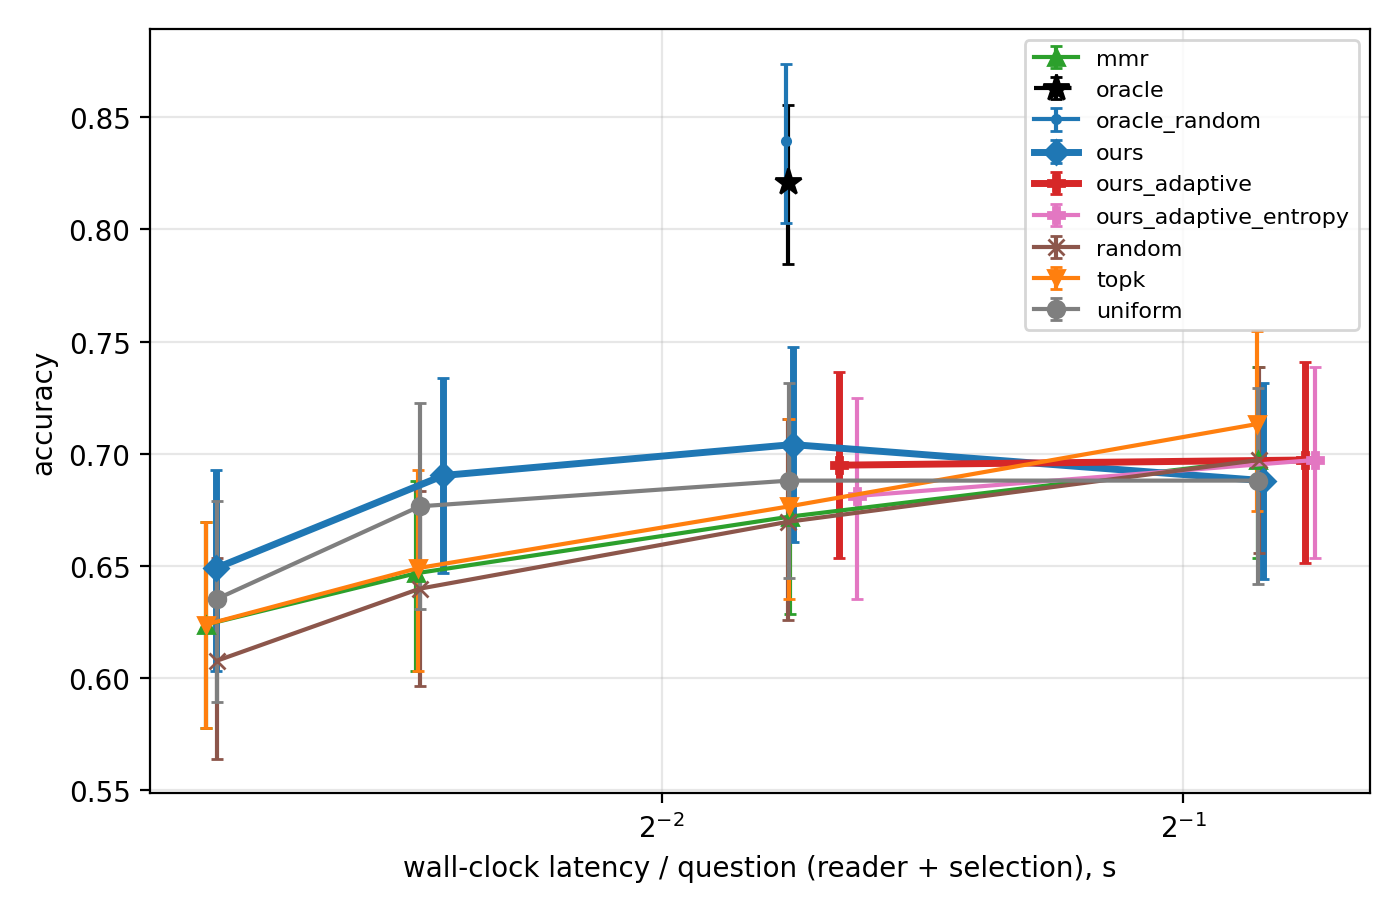

frames_needed


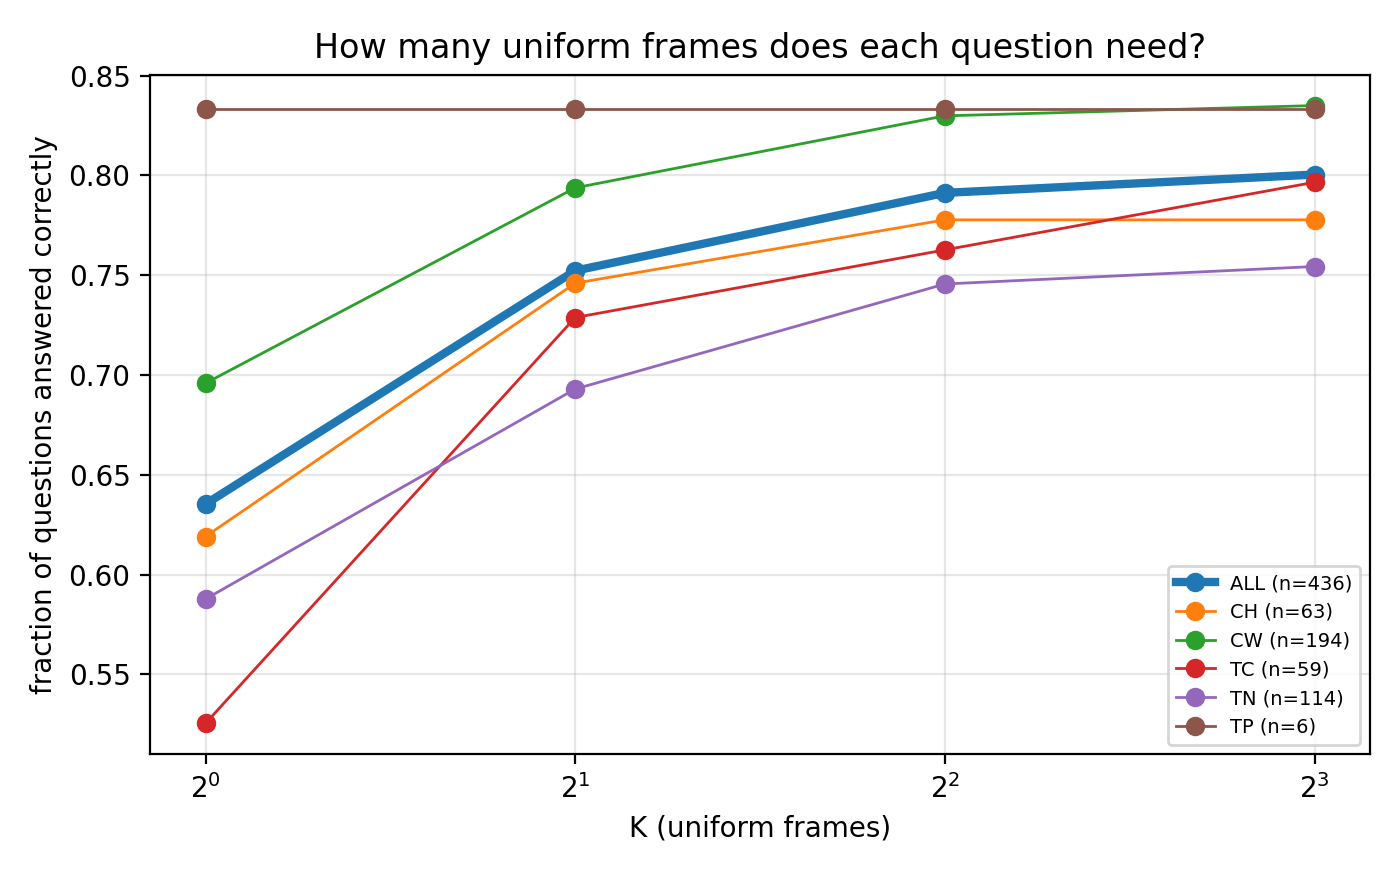

needle_hit_rate


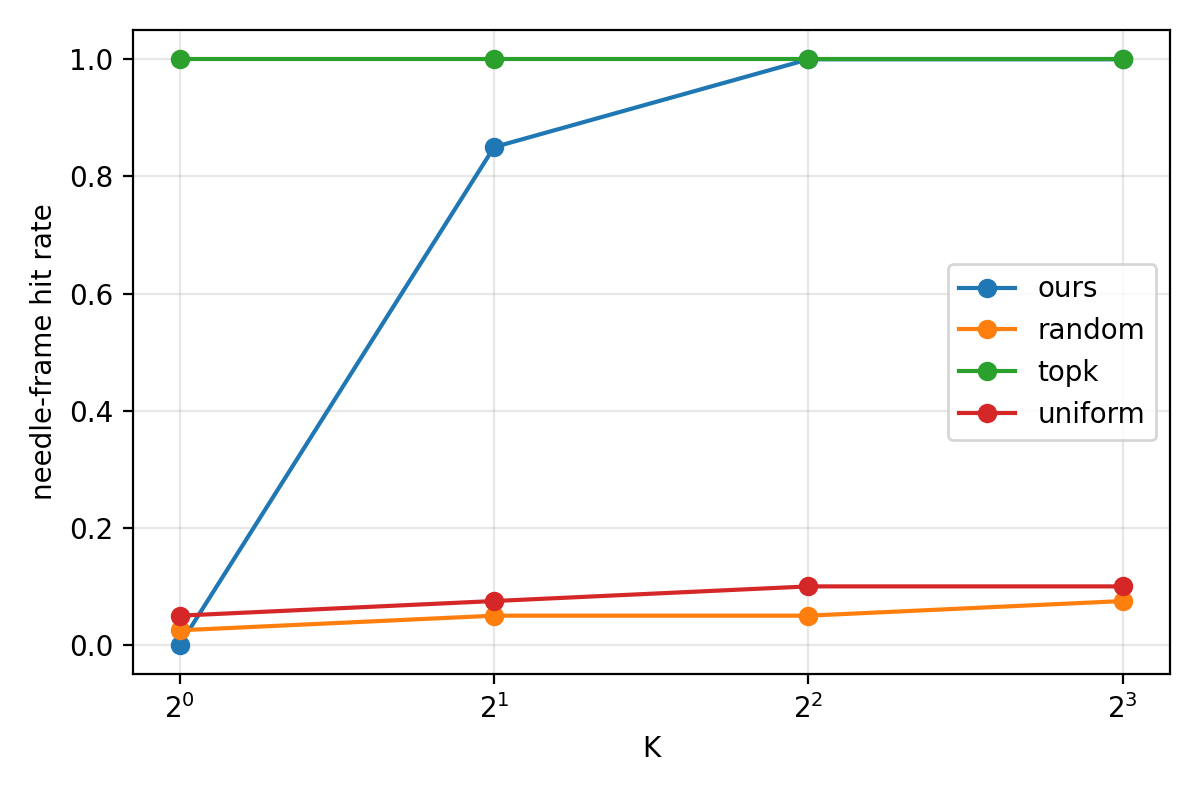

In [16]:
from IPython.display import Image, display
for f in ['acc_vs_K', 'pareto_gflops', 'pareto_latency', 'frames_needed', 'needle_hit_rate']:
    p = f'results/nextqa/report/{f}.png'
    if os.path.exists(p):
        print(f); display(Image(p))

In [17]:
sh('zip -qr results_fast.zip results/nextqa')
from google.colab import files
files.download('results_fast.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>